# Exploratory Data Analysis

## Objective

This notebook investigates the AI4I 2020 Predictive Maintenance
Dataset to identify patterns associated with machine failure.

The analysis includes:
- Distribution of machine failures
- Machine failure frequency by type
- Sensor measurement distributions
- Comparison of sensor measurements by failure status
- Relationships between numerical features
- Key findings to inform machine-learning modelling


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/raw/ai4i2020.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


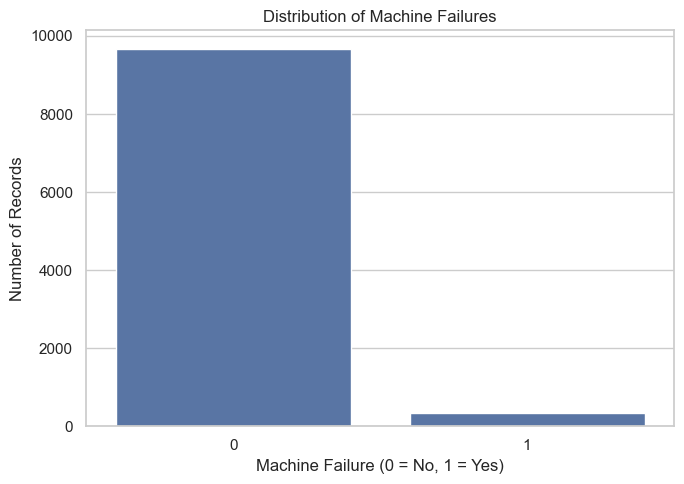

In [11]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Machine failure"
)

ax.set_title("Distribution of Machine Failures")
ax.set_xlabel("Machine Failure (0 = No, 1 = Yes)")
ax.set_ylabel("Number of Records")

plt.tight_layout()
plt.show()

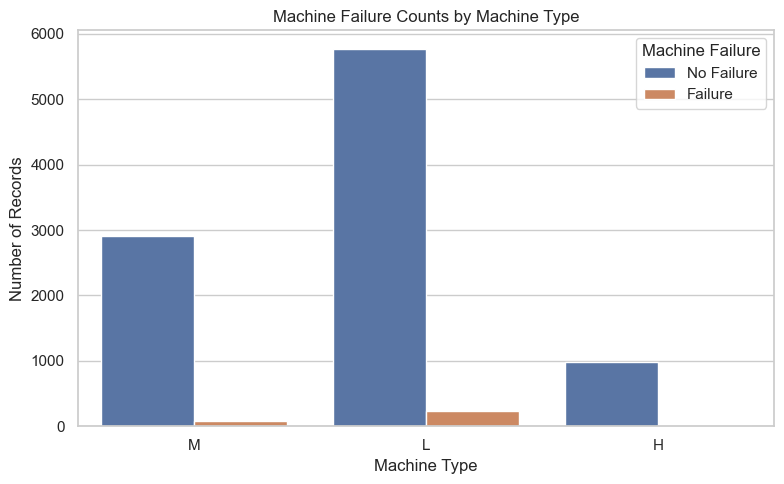

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Type",
    hue="Machine failure"
)

plt.title("Machine Failure Counts by Machine Type")
plt.xlabel("Machine Type")
plt.ylabel("Number of Records")
plt.legend(title="Machine Failure", labels=["No Failure", "Failure"])

plt.tight_layout()
plt.show()

In [13]:
failure_by_type = (
    df.groupby("Type")["Machine failure"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Total Records",
        "sum": "Failure Records",
        "mean": "Failure Rate"
    })
)

failure_by_type["Failure Rate"] *= 100

failure_by_type.round(2)

,Total Records,Failure Records,Failure Rate
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77


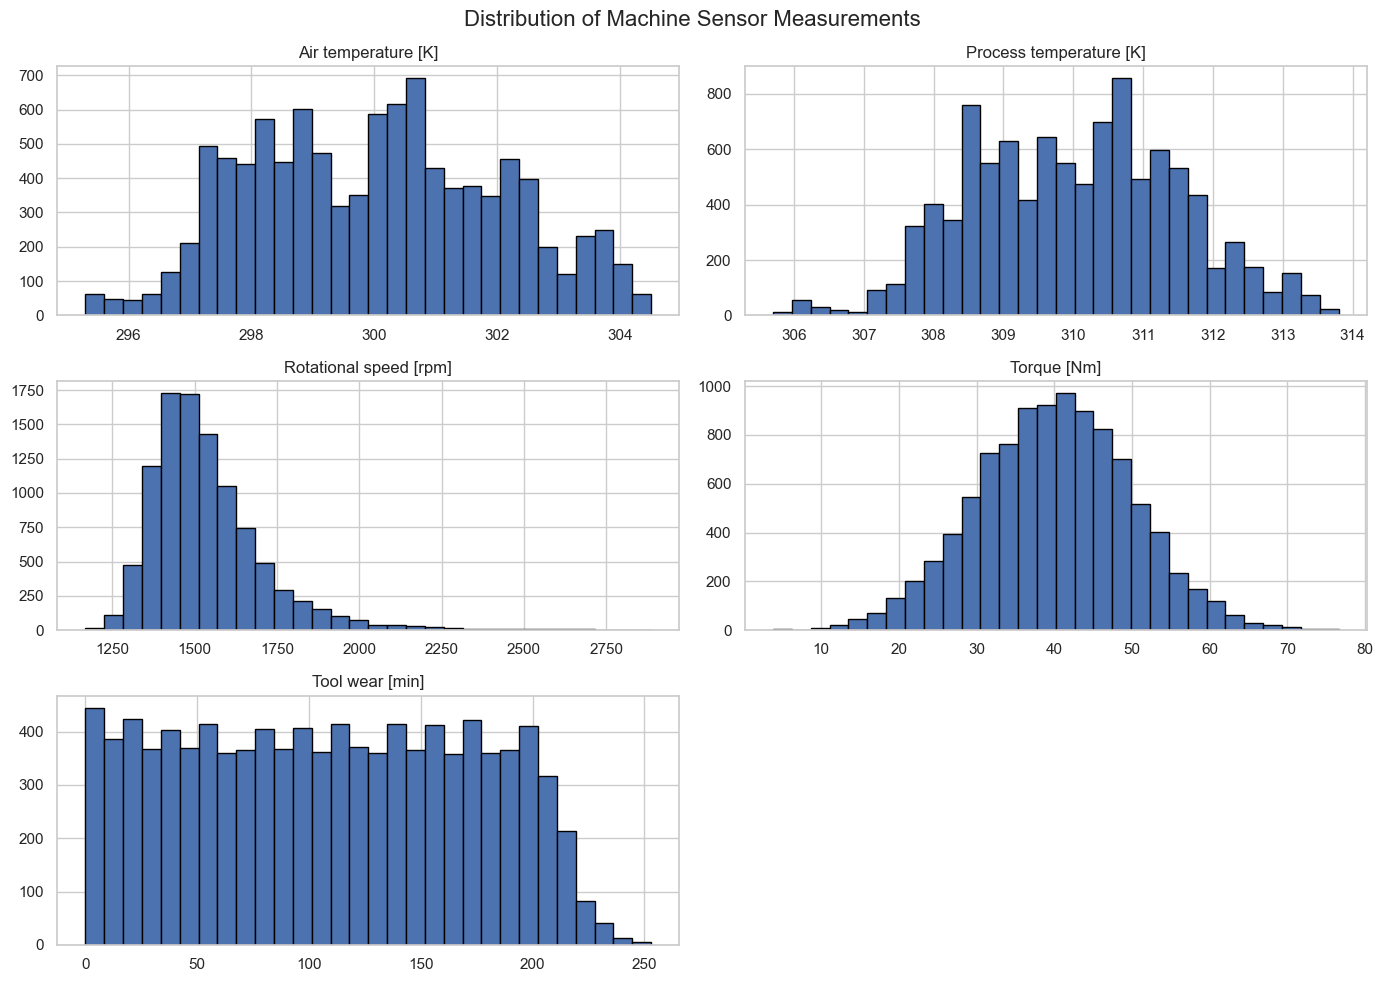

In [14]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numerical_features].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Machine Sensor Measurements",
    fontsize=16
)

plt.tight_layout()
plt.show()

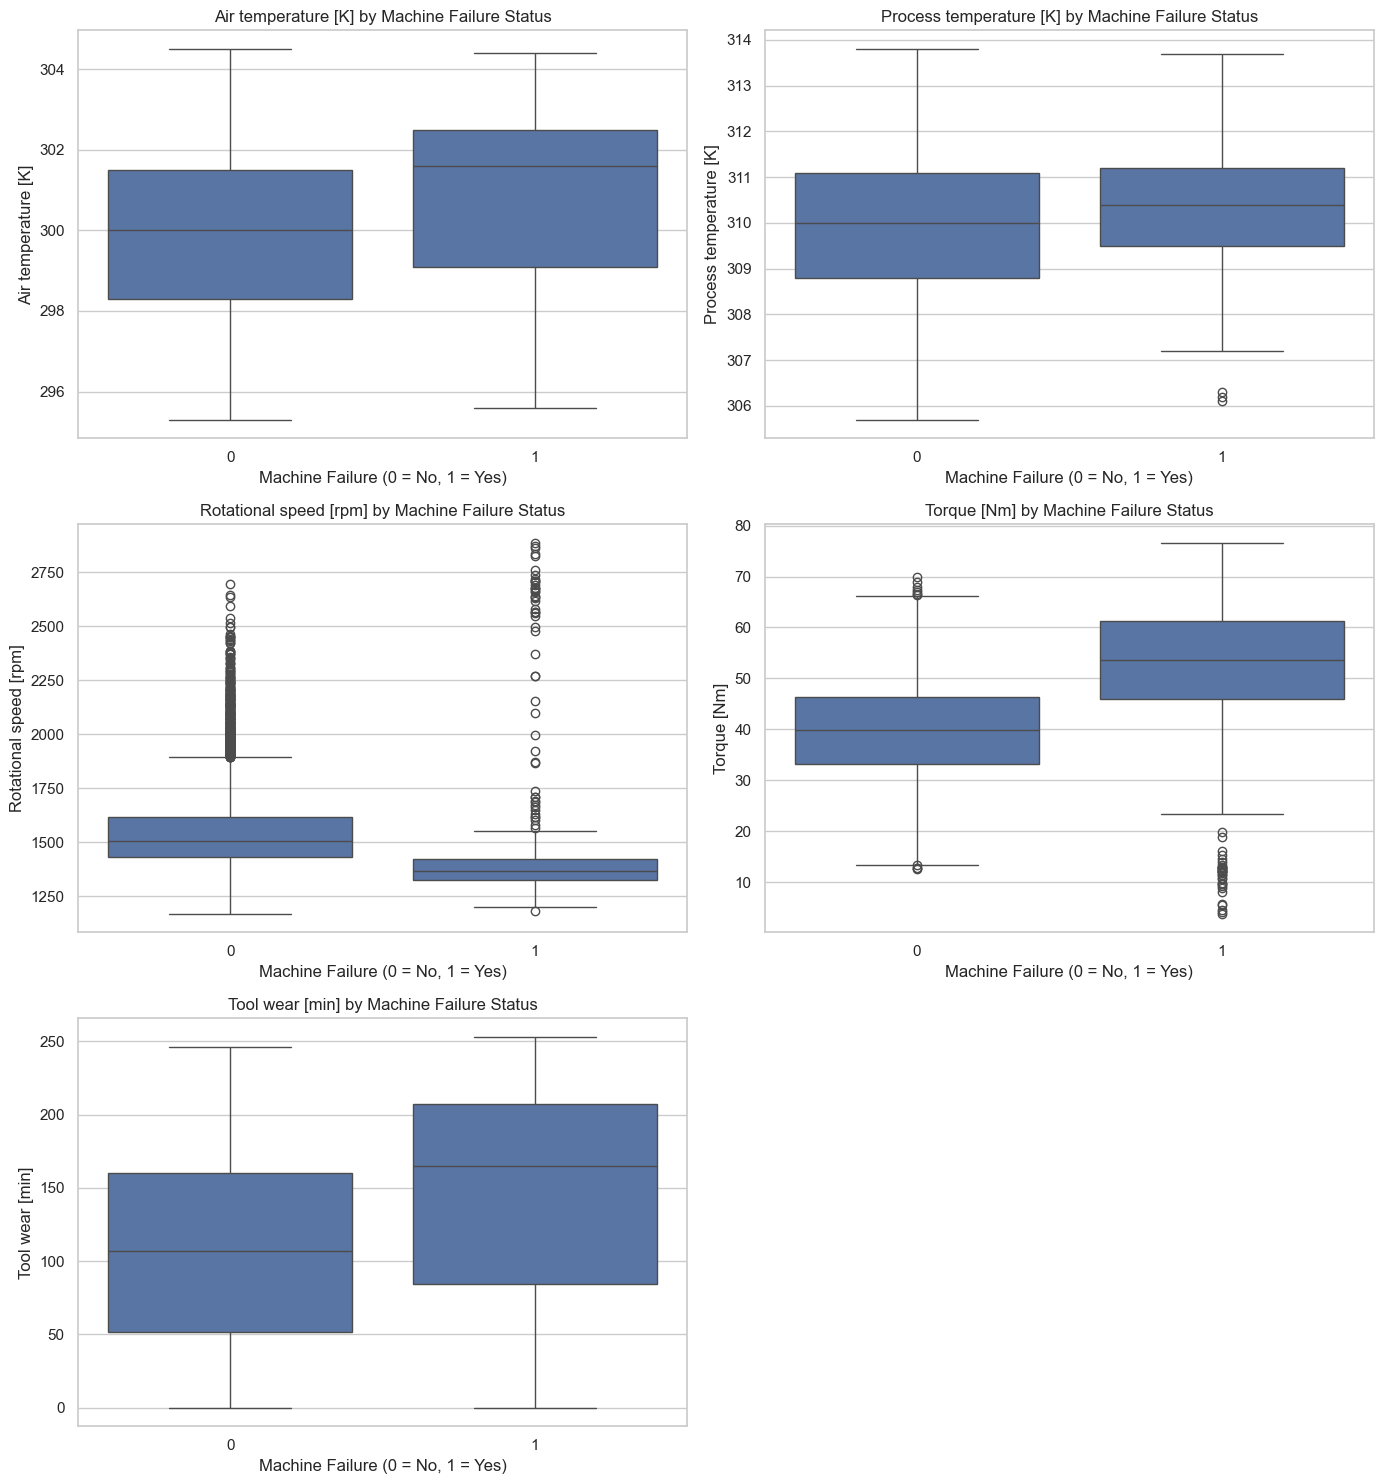

In [15]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14, 15)
)

axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{feature} by Machine Failure Status"
    )

    axes[i].set_xlabel("Machine Failure (0 = No, 1 = Yes)")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

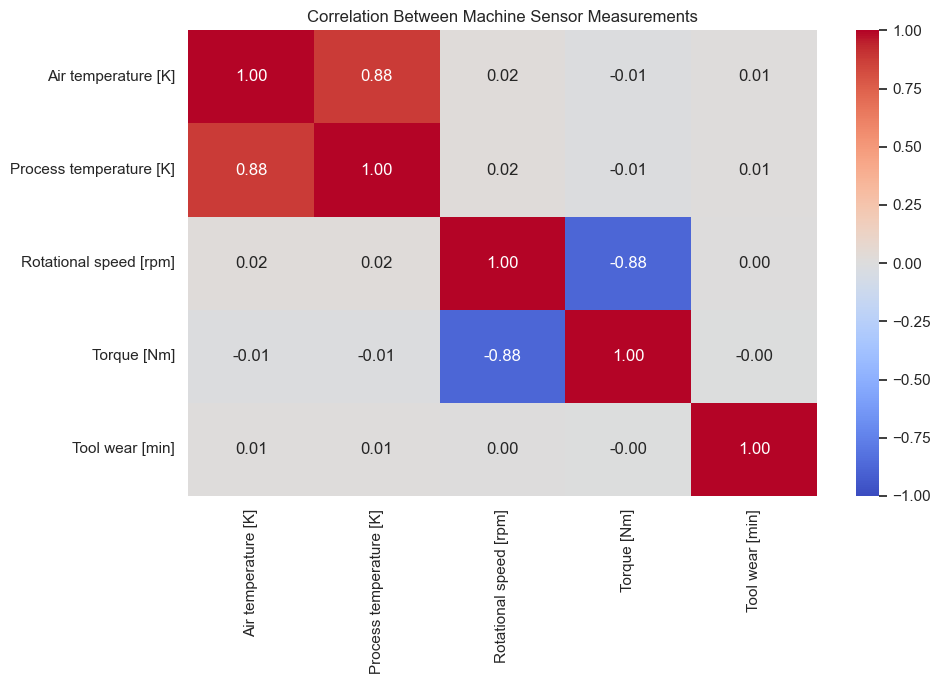

In [16]:
correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Machine Sensor Measurements")

plt.tight_layout()
plt.show()

In [17]:
sensor_comparison = (
    df.groupby("Machine failure")[numerical_features]
    .mean()
    .T
)

sensor_comparison.columns = [
    "No Failure",
    "Failure"
]

sensor_comparison["Difference"] = (
    sensor_comparison["Failure"]
    - sensor_comparison["No Failure"]
)

sensor_comparison.round(2)

,No Failure,Failure,Difference
Air temperature [K],299.97,300.89,0.91
Process temperature [K],310.00,310.29,0.29
Rotational speed [rpm],1540.26,1496.49,-43.77
Torque [Nm],39.63,50.17,10.54
Tool wear [min],106.69,143.78,37.09


## Key Findings

1. Machine failure is an imbalanced classification problem.
2. Sensor measurements have different distributions across the dataset.
3. Failure rates should be compared across machine types rather than
   relying only on raw failure counts.
4. Correlation analysis helps identify relationships between numerical
   sensor measurements.
5. Exploratory findings inform feature selection and model evaluation.
6. Further modelling is required to determine how well the sensor
   measurements can predict machine failure on unseen records.

## Next Step

The findings from this notebook are used to inform the feature selection,
model training, threshold selection and evaluation performed in
`03_model_training.ipynb`.